In [1]:
try:
    import emoji
except ImportError:
    !pip install -q emoji
    import emoji


# Paso 1 — Carga, unificación y exploración del dataset

In [2]:
import pandas as pd
import numpy as np
import re
import json

# Carga y unificación de archivos
archivos = [
    'feedback_curso_universitario.csv',
    'feedback_curso_universitario2.csv',
    'feedback_curso_universitario3.csv'
]

dfs = []
for archivo in archivos:
    try:
        temp_df = pd.read_csv(archivo)
        temp_df['origen_archivo'] = archivo
        dfs.append(temp_df)
    except FileNotFoundError:
        print(f"Advertencia: No se encontró {archivo}. Asegúrate de subirlo a Colab.")

df = pd.concat(dfs, ignore_index=True)

# Remover filas espurias donde id == 'id'
filtro_cabecera = df['id'].astype(str).str.lower() == 'id'
df_clean = df[~filtro_cabecera].copy()

# Analizar valores únicos y problemas
resumen = {
    "total_filas_original": len(df),
    "filas_cabecera_removidas": int(filtro_cabecera.sum()),
    "total_filas_validas": len(df_clean),
    "distribucion_origen": df_clean['origen_archivo'].value_counts().to_dict(),
    "nulos_por_columna": df_clean.isnull().sum().to_dict(),
    "duplicados_completos": int(df_clean.duplicated().sum()),
    "duplicados_feedback": int(df_clean.duplicated(subset=['feedback']).sum()),
    "valores_unicos_polaridad": df_clean['polaridad_basica'].value_counts().to_dict(),
    "valores_unicos_grano_fino": df_clean['grano_fino'].value_counts().to_dict(),
    "valores_unicos_emocion": df_clean['emocion'].value_counts().to_dict(),
    "valores_unicos_curso": df_clean['curso'].value_counts().to_dict(),
    "valores_unicos_semestre": df_clean['semestre'].value_counts().to_dict(),
}

print(json.dumps(resumen, indent=2, ensure_ascii=False))



{
  "total_filas_original": 622,
  "filas_cabecera_removidas": 4,
  "total_filas_validas": 618,
  "distribucion_origen": {
    "feedback_curso_universitario2.csv": 405,
    "feedback_curso_universitario.csv": 193,
    "feedback_curso_universitario3.csv": 20
  },
  "nulos_por_columna": {
    "id": 0,
    "curso": 0,
    "feedback": 0,
    "polaridad_basica": 0,
    "grano_fino": 0,
    "emocion": 0,
    "aspectos": 0,
    "semestre": 0,
    "origen_archivo": 0
  },
  "duplicados_completos": 0,
  "duplicados_feedback": 0,
  "valores_unicos_polaridad": {
    "neutral": 215,
    "negativo": 124,
    "['negativo']": 81,
    "positivo": 70,
    "['positivo']": 66,
    "['neutral']": 44,
    "positiva": 12,
    "[\"['positivo']\"]": 5,
    "['posicion']": 1
  },
  "valores_unicos_grano_fino": {
    "3": 612,
    "4": 5,
    "5": 1
  },
  "valores_unicos_emocion": {
    "neutral": 610,
    "sorpresa": 2,
    "alegría": 2,
    "enojo": 1,
    "miedo": 1,
    "tristeza": 1,
    "enfriamiento": 1

In [3]:
# Inspeccionar aspectos y anomalías
print("Muestra de aspectos:")
print(df_clean['aspectos'].value_counts().head(10))

print("\nAspectos únicos o vacíos:")
print("Aspectos como '[]':", (df_clean['aspectos'] == '[]').sum())
print("Aspectos no vacíos:", (df_clean['aspectos'] != '[]').sum())

# Revisar typos en cursos
print("\nCursos:")
print(df_clean['curso'].unique())


Muestra de aspectos:
aspectos
[{"aspecto": "contenidos", "sentimiento": "positivo"}]                                                                                            140
[]                                                                                                                                                 60
[{"aspecto": "contenidos", "sentimiento": "neutral"}]                                                                                              23
[{"aspecto": "Contenido y pertinencia", "sentimiento": "positivo"}]                                                                                 9
[{"aspecto": "contenidos", "sentimiento": "positivo"}, {"aspecto": "parciales", "sentimiento": "negativo"}]                                         8
[{"aspecto": "contenidos", "sentimiento": "positivo"}, {"aspecto": "dificultad de las preguntas en los parciales", "sentimiento": "neutral"}]       8
[{"aspecto": "contenidos", "sentimiento": "positivo"}, {"aspecto": "di

# Prompt
Actúa como un experto en NLP y Calidad de Datos. Analiza el siguiente resumen de un dataset de feedback universitario:

[Se adjuntó el JSON `resumen` generado en la celda anterior (conteos de nulos, duplicados y valores únicos por columna)]

Por favor, entrega un diagnóstico técnico cubriendo:
1. Problemas de consistencia en el esquema y formatos observados (listas como strings, etiquetas malformadas, etc.).
2. Errores potenciales en el diseño de las taxonomías (polaridad, grano fino, emociones).
3. Recomendaciones prioritarias de saneamiento antes de entrenar un modelo supervisado.






# Respuesta del prompt

Se obtuvo un total bruto de 622 registros, de los cuales 618 son registros de datos válidos y 4 corresponden a cabeceras duplicadas.
1. Consistencia en el Esquema y Formatos
* Inyección de cabeceras en los datos: Se detectaron 4 filas donde los valores de cada columna repiten literalmente el nombre del campo (id="id", curso="curso", feedback="feedback"). Ocurren principalmente por concatenaciones manuales previas sin omitir el encabezado.
* Serialización inconsistente de cadenas y listas (polaridad_basica):La columna contiene una mezcla de texto plano (neutral, negativo, positivo), listas en formato string (['negativo'], ['neutral']) e incluso anidamientos dobles con comillas escapadas ("[\"['positivo']\"]"). Además, existe un error tipográfico ('posicion') y variaciones léxicas de género ('positiva').
* Representación de datos estructurados (aspectos):La columna almacena cadenas que simulan listas de diccionarios JSON (ej. [{"aspecto": "contenidos", "sentimiento": "positivo"}]) junto con listas vacías []. No están parseadas como estructuras nativas y presentan inconsistencias en mayúsculas/minúsculas y nivel de granularidad (ej. "contenidos" vs. "Contenido y pertinencia" vs. "dificultad de las preguntas en los parciales").
* Faltantes implícitos:Aunque técnicamente no hay valores NaN/null en Pandas (0 faltantes en todas las columnas), hay ausencia de información disfrazada como texto: 60 registros presentan listas vacías en aspectos ([]).
2. Errores Potenciales en el Diseño de las Taxonomías
* Colapso severo en grano_fino:De los 618 registros, 612 filas (99.03%) tienen valor 3, 5 tienen valor 4 y solo 1 tiene valor 5. Los valores 1 y 2 están completamente ausentes. La escala de 1 a 5 está rota o fue asignada por defecto sin variabilidad real, haciéndola inútil para regresión o clasificación ordinal.
* Desbalance extremo y etiquetas espurias en emocion:La clase neutral acapara 610 de los 618 registros (98.71%). Las demás emociones apenas aparecen 1 o 2 veces (alegría: 2, sorpresa: 2, enojo: 1, miedo: 1, tristeza: 1), además de incluir una categoría anómala/no estándar (enfriamiento: 1). No hay soporte estadístico para entrenar un clasificador multiclase de emociones con esta distribución.
* Discordancia entre polaridad básica y granularidad:Existen múltiples casos donde polaridad_basica fue catalogada como neutral, mientras que la columna aspectos desglosa sentimientos fuertemente contrastados (ej. contenido positivo pero parciales negativos).
3. Recomendaciones Prioritarias de Saneamiento
* Eliminar filas espurias de cabecera:Filtrar cualquier registro donde df['id'].str.lower() == 'id'.
* Normalizar y canónizar polaridad_basica: Aplicar expresiones regulares para extraer la palabra clave interna, corregir errores tipográficos (posicion $\rightarrow$ positivo, positiva $\rightarrow$ positivo) y restringir el target a tres clases estrictas: positivo, negativo, neutral.
* Parsear y estandarizar la columna aspectos: Convertir las cadenas en objetos nativos con json.loads o ast.literal_eval. Mapear las categorías de aspectos a una taxonomía fija y controlada (ej. agrupar "dificultad de las preguntas en los parciales" y "parciales" bajo la categoría "evaluación").
* Corregir erratas en variables categóricas:El curso Sistemas opertativos tiene una falta de ortografía sistemática (145 ocurrencias) que debe normalizarse a Sistemas operativos.
* Revaluar el uso de grano_fino y emocion:Descartar estas dos columnas para entrenamiento supervisado directo en su estado actual, o bien re-etiquetarlas mediante un LLM (zero-shot/few-shot) para dotarlas de una distribución real y representativa.

## Correcion y unificacion dado por IA

In [4]:
import pandas as pd
import json
import ast
import re

# 1. Cargar y concatenar los archivos
archivos = [
    'feedback_curso_universitario.csv',
    'feedback_curso_universitario2.csv',
    'feedback_curso_universitario3.csv'
]

dfs = []
for archivo in archivos:
    try:
        temp_df = pd.read_csv(archivo)
        temp_df['origen_archivo'] = archivo
        dfs.append(temp_df)
    except FileNotFoundError:
        print(f"Advertencia: No se encontró {archivo}")

df_raw = pd.concat(dfs, ignore_index=True)

# 2. Eliminar cabeceras redundantes incrustadas en los datos
filtro_cabecera = df_raw['id'].astype(str).str.lower().str.strip() == 'id'
df = df_raw[~filtro_cabecera].copy()

# 3. Corrección tipográfica en nombres de cursos
mapeo_cursos = {
    'Sistemas opertativos': 'Sistemas operativos'
}
df['curso'] = df['curso'].replace(mapeo_cursos).str.strip()

# 4. Normalización canónica de 'polaridad_basica'
def corregir_polaridad(val):
    if pd.isna(val):
        return 'desconocido'
    # Extraer solo caracteres alfabéticos
    v = re.sub(r"[^a-záéíóúñ]", "", str(val).lower().strip())
    mapeo = {
        'positivo': 'positivo',
        'positiva': 'positivo',
        'posicion': 'positivo',
        'negativo': 'negativo',
        'negativa': 'negativo',
        'neutral': 'neutral',
        'neutro': 'neutral'
    }
    return mapeo.get(v, 'otro')

df['polaridad_basica'] = df['polaridad_basica'].apply(corregir_polaridad)

# 5. Parseo seguro de la columna 'aspectos' a estructuras nativas
def parsear_aspectos(val):
    if pd.isna(val) or str(val).strip() in ['', '[]']:
        return []
    val_str = str(val).strip()
    # Intentar primero con json estándar
    try:
        resultado = json.loads(val_str)
        if isinstance(resultado, list):
            return resultado
    except Exception:
        pass
    # Fallback con ast.literal_eval por si contiene comillas simples
    try:
        resultado = ast.literal_eval(val_str)
        if isinstance(resultado, list):
            return resultado
    except Exception:
        pass
    return []

df['aspectos_estructurados'] = df['aspectos'].apply(parsear_aspectos)

# 6. Casteo de tipos de datos
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df['grano_fino'] = pd.to_numeric(df['grano_fino'], errors='coerce')
df['feedback'] = df['feedback'].astype(str).str.strip()
df['semestre'] = df['semestre'].astype(str).str.strip()

# 7. Reiniciar índice y guardar resultado limpio
nombre_nuevo_csv = '1_feedback_universitario_corregido.csv'
df = df.reset_index(drop=True)
df.to_csv(nombre_nuevo_csv, index=False)

# Verificación de resultados
print("=== RESUMEN TRAS CORRECCIONES ===")
print(f"Total registros válidos: {len(df)}")
print("\nDistribución de Polaridad Básica:")
print(df['polaridad_basica'].value_counts())
print("\nDistribución de Cursos:")
print(df['curso'].value_counts())
print("\nRegistros con aspectos desglosados:", (df['aspectos_estructurados'].apply(len) > 0).sum())
print("Registros con aspectos vacíos ([]):", (df['aspectos_estructurados'].apply(len) == 0).sum())
print("\n=== ARCHIVO EXPORTADO ===")
print(f"Archivo exportado: {nombre_nuevo_csv}")

=== RESUMEN TRAS CORRECCIONES ===
Total registros válidos: 618

Distribución de Polaridad Básica:
polaridad_basica
neutral     259
negativo    205
positivo    154
Name: count, dtype: int64

Distribución de Cursos:
curso
Sistemas operativos            145
Arquitectura del computador     92
Programacion paralela           85
Sistemas distribuidos           77
Sistemas Inteligentes           76
Fundamentos de programación     73
Bases de datos                  70
Name: count, dtype: int64

Registros con aspectos desglosados: 558
Registros con aspectos vacíos ([]): 60

=== ARCHIVO EXPORTADO ===
Archivo exportado: 1_feedback_universitario_corregido.csv


## Paso 2 (Análisis, preprocesamiento, normalización y etiquetado)

In [5]:
# Instalar librería emoji (solo si falta)
try:
    import emoji
except ImportError:
    !pip install -q emoji
    import emoji

import pandas as pd
import numpy as np
import re
import emoji

# 1. Cargar el dataset consolidado del Paso 1
df = pd.read_csv('1_feedback_universitario_corregido.csv')
print(f"Registros cargados: {len(df)}")

# 2. Diccionario de intensificadores y reducciones comunes
INTENSIFICADORES = {
    r'\bsuuuper\b|\bsuper+\b': 'súper',
    r'\bree+\b': 're',
    r'\bmu+y+\b': 'muy',
    r'\bpeesi+mo\b|\bpesimoo+\b': 'pésimo',
    r'\bexceleente+\b': 'excelente',
    r'\bbueni+simo\b': 'buenísimo'
}

def normalizar_texto(texto: str) -> str:
    """Normaliza texto: trata nulos, emojis, caracteres repetidos e intensificadores."""
    if pd.isna(texto) or not str(texto).strip():
        return ""

    texto = str(texto)

    # a. Convertir emojis en representaciones textuales en español (:cara_feliz:)
    texto = emoji.demojize(texto, language='es')

    # b. Reducir caracteres repetidos consecutivos (ej. "bueeeno" -> "bueno", "siempreee" -> "siempre")
    texto = re.sub(r'(.)\1{2,}', r'\1\1', texto)

    # c. Estandarizar intensificadores alargados
    for patron, reemplazo in INTENSIFICADORES.items():
        texto = re.sub(patron, reemplazo, texto, flags=re.IGNORECASE)

    # d. Limpiar espacios redundantes y saltos de línea
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

# 3. Aplicar normalización al texto del feedback
df['feedback_limpio'] = df['feedback'].apply(normalizar_texto)

# 4. Tratar textos vacíos o duplicados resultantes tras la normalización
df = df[df['feedback_limpio'] != ""].drop_duplicates(subset=['feedback_limpio']).reset_index(drop=True)

# 5. Detección y extracción de casos contrastantes / ambiguos
patron_contraste = r'\b(?:pero|sin embargo|aunque|no obstante|por el contrario)\b'
df['es_contrastante'] = df['feedback_limpio'].str.contains(patron_contraste, case=False, regex=True)

print(f"Total registros únicos y limpios: {len(df)}")
print(f"Comentarios con cláusulas de contraste (ambiguos potenciales): {df['es_contrastante'].sum()}")

# Exportar dataset listo para modelado
nombre_nuevo_csv = '2_feedback_preprocesado_final.csv'
df.to_csv(nombre_nuevo_csv, index=False, encoding='utf-8')
print(f"Archivo exportado: {nombre_nuevo_csv}")

Registros cargados: 618
Total registros únicos y limpios: 618
Comentarios con cláusulas de contraste (ambiguos potenciales): 472
Archivo exportado: 2_feedback_preprocesado_final.csv


# Prompt
Actúa como un anotador lingüístico senior. A continuación tienes un conjunto de comentarios de estudiantes que contienen opiniones mixtas/contrastantes:

[Se adjuntaron en JSON 5 comentarios con conectores adversativos del archivo feedback_curso_universitario.csv: ids 3, 5, 6, 9 y 11]

Instrucciones:
1. Define una guía formal de etiquetado (guía de desempate) para calificar comentarios con cláusulas contrastantes (ej: 'El contenido fue bueno, pero el profesor no explicó bien').
2. Reevalúa cada uno de los 5 casos anteriores indicando:
   - Polaridad global sugerida (Positivo / Negativo / Neutral / Mixto)
   - Justificación basada en la guía propuesta

# Respuesta prompt
#### 1. Guía de Etiquetado y Reglas de Desempate

Cuando un comentario contiene polaridades encontradas (opiniones mixtas o cláusulas contrastantes), se aplican las siguientes reglas jerárquicas:

1. **Regla de Cierre por Adversativa:** En construcciones con conectores adversativos fuertes (*pero*, *sin embargo*, *no obstante*), la cláusula que sigue al conector tiene mayor peso pragmático, pues introduce la objeción o conclusión del estudiante sobre el aspecto previo.
* *Ejemplo:* "El contenido fue excelente, pero las evaluaciones no tuvieron sentido" $\rightarrow$ **Negativo** (o **Mixto** si la taxonomía lo admite).


2. **Evaluación de Severidad del Objeto Pedagógico:** Si el estudiante califica positivamente el tema o el contenido (interés general), pero reprueba la evaluación, la pedagogía o la disponibilidad del docente, la experiencia global se cataloga según la fricción docente/académica.
3. **Manejo de la Concesión (*aunque*):** En cláusulas concesivas (*aunque*), la cláusula principal suele subordinar a la concesiva.
* *Ejemplo:* "El curso fue bueno, aunque algo pesado" $\rightarrow$ **Positivo**.



---

#### 2. Revisión de Casos Reales del Dataset

| ID | Texto Limpio | Polaridad en CSV | Polaridad Sugerida | Justificación |
| --- | --- | --- | --- | --- |
| **3** | *"El contenido fue bastante interesante, aunque algunas partes pudieron haber sido más detalladas para facilitar comprensión."* | `['neutral']` | **Positivo** | La cláusula principal es un elogio claro (*"bastante interesante"*). La concesión (*"aunque..."*) es una sugerencia constructiva de mejora, no un rechazo. |
| **5** | *"El horario fue justo, no me dejó demasiado tiempo libre. Los parciales fueron desafiantes pero gratificantes."* | `['positivo']` | **Positivo** | La adversativa cierra en un aspecto favorable (*"gratificantes"*), compensando el desafío. La etiqueta original es consistente con el cierre. |
| **6** | *"En general, el curso ha sido bastante desafiante pero también fascinante. Los materiales se han presentado de manera clara..."* | `['negativo']` | **Positivo** | **Etiqueta original incorrecta**. El comentario califica el curso de *"fascinante"* y destaca la claridad de los materiales. Clasificarlo como negativo es un error evidente de anotación previa. |
| **9** | *"El contenido fue amplio y útil, pero la disponibilidad de recursos en el aula digital era limitada. Me siento sorprendido..."* | `['posicion']` | **Negativo / Mixto** | Tras la conjunción *"pero"*, introduce una queja operativa sobre los recursos digitales y frustración. La etiqueta original (`posicion`) era una errata y el sentimiento real es crítico. |
| **11** | *"Desafortunadamente, mi opinión general del curso no fue muy animada... Me encontré con momentos de miedo ante la dificultad... Sin embargo, hubo un aspecto positivo: la organización..."* | `['negativo']` | **Negativo** | A pesar de reconocer una organización favorable al final, la tesis explícita del estudiante comienza con *"mi opinión general del curso no fue muy animada"* y describe incomodidad predominante. La etiqueta negativa se sostiene. |

## Codigo realizado con respuesta del prompt

In [6]:
import pandas as pd
import numpy as np
import re
import emoji

# 1. Cargar el dataset unificado del Paso 1
# (Soporta feedback_unificado_limpio.csv o feedback_universitario_corregido.csv)
try:
    df = pd.read_csv('2_feedback_preprocesado_final.csv')
except FileNotFoundError:
    print("No encontrado")

print(f"Registros originales cargados: {len(df)}")

# 2. Diccionario de intensificadores y reducciones léxicas
INTENSIFICADORES = {
    r'\bsuuuper\b|\bsuper+\b': 'súper',
    r'\bree+\b': 're',
    r'\bmu+y+\b': 'muy',
    r'\bpeesi+mo\b|\bpesimoo+\b': 'pésimo',
    r'\bexceleente+\b': 'excelente',
    r'\bbueni+simo\b': 'buenísimo'
}

def normalizar_texto(texto: str) -> str:
    """Normaliza texto: emojis a texto, caracteres repetidos, intensificadores y espacios."""
    if pd.isna(texto) or not str(texto).strip():
        return ""

    texto = str(texto)
    # a. Convertir emojis a descripciones en español (:cara_feliz:)
    texto = emoji.demojize(texto, language='es')
    # b. Reducir caracteres repetidos consecutivos (ej. "bueeeno" -> "bueno")
    texto = re.sub(r'(.)\1{2,}', r'\1\1', texto)
    # c. Estandarizar variantes de intensificadores
    for patron, reemplazo in INTENSIFICADORES.items():
        texto = re.sub(patron, reemplazo, texto, flags=re.IGNORECASE)
    # d. Limpiar espacios redundantes
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

# Aplicar normalización textual y filtrar duplicados/vacíos
df['feedback_limpio'] = df['feedback'].apply(normalizar_texto)
df = df[df['feedback_limpio'] != ""].drop_duplicates(subset=['feedback_limpio']).reset_index(drop=True)

# 3. Limpieza de base de las etiquetas de polaridad (eliminar ['...'], comillas y erratas léxicas)
def normalizar_etiqueta_base(val: str) -> str:
    if pd.isna(val):
        return 'neutral'
    v = re.sub(r"[^a-záéíóúñ]", "", str(val).lower().strip())
    mapeo = {
        'positivo': 'positivo',
        'positiva': 'positivo',
        'posicion': 'positivo',
        'negativo': 'negativo',
        'negativa': 'negativo',
        'neutral': 'neutral',
        'neutro': 'neutral'
    }
    return mapeo.get(v, 'neutral')

df['polaridad_final'] = df['polaridad_basica'].apply(normalizar_etiqueta_base)

# 4. APLICACIÓN DE LA GUÍA DEL LLM: Resolución de casos ambiguos y corrección de etiquetado
# Reglas de desempate aplicadas a los casos auditados
correcciones_llm = {
    3: 'positivo',   # Concesiva con juicio principal favorable dominante
    6: 'positivo',   # Error de origen corregido: feedback altamente elogioso ("fascinante", "clara")
    9: 'negativo',   # Cláusula adversativa introduce queja crítica y frustración
    11: 'negativo'   # Tesis explícita negativa prevalece sobre aspectos neutros
}

# IMPORTANTE: los 'id' se reinician en cada CSV (618 filas, solo 405 ids distintos).
# Los 5 casos auditados pertenecen al archivo 1, así que la llave es (archivo, id).
ARCHIVO_AUDITADO = 'feedback_curso_universitario.csv'
df['id_num'] = pd.to_numeric(df['id'], errors='coerce')
for id_caso, nueva_etiqueta in correcciones_llm.items():
    mascara = (df['id_num'] == id_caso) & (df['origen_archivo'] == ARCHIVO_AUDITADO)
    assert mascara.sum() == 1, f"El id {id_caso} debe identificar exactamente 1 fila (halladas: {mascara.sum()})"
    df.loc[mascara, 'polaridad_final'] = nueva_etiqueta

df.drop(columns=['id_num'], inplace=True)

# 5. Detección de comentarios con cláusulas contrastantes
patron_contraste = r'\b(?:pero|sin embargo|aunque|no obstante|por el contrario)\b'
df['es_contrastante'] = df['feedback_limpio'].str.contains(patron_contraste, case=False, regex=True)

# 6. Guardar en un NUEVO archivo CSV
nombre_nuevo_csv = '3_feedback_preprocesado_etiquetado.csv'
df.to_csv(nombre_nuevo_csv, index=False, encoding='utf-8')

# Verificación
print(f"\nProceso finalizado. Nuevo archivo generado: {nombre_nuevo_csv}")
print(f"Total registros procesados: {len(df)}")
print(f"Comentarios contrastantes detectados: {df['es_contrastante'].sum()}")
print("\nDistribución final de polaridad:")
print(df['polaridad_final'].value_counts())


Registros originales cargados: 618



Proceso finalizado. Nuevo archivo generado: 3_feedback_preprocesado_etiquetado.csv
Total registros procesados: 618
Comentarios contrastantes detectados: 472

Distribución final de polaridad:
polaridad_final
neutral     258
negativo    205
positivo    155
Name: count, dtype: int64


#Paso 3 Division de datos en entrenamiento(80%) y pruebas(20%)

####Criterios de la division de datos(entrenamiento / pruebas):

1. Se separan los datos en 2 bloques independientes. Un bloque con el 80% destinado para que los algoritmos aprendan los patrones encontrados en el feedback de los estudiantes, y el bloque con el 20% restante se deja de lado inicialmente guardandolo para ser usado como los datos de prueba para el modelo final, verificando que aprendio correctamente del primer bloque que se le entrego.

2. Para evitar que un grupo quede sin suficientes feedback de una categoria en especifico, usaremos la funcion stratify=y que obliga a que los porcentajes de polaridad sean equitativos entre ambos bloques.

3. Antes de la division tambien nos aseguramos de elaborar un barajado aleatorio de los datos, tratando de eliminar asi cualquier orden autoimpuesto que pudo haber estado en ellos en un inicio, para esto proporcionamos una seed estatica para que el barajado sea el mismo cada vez que se requiera.








In [7]:
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset procesado y etiquetado del Paso 2
try:
    df = pd.read_csv('3_feedback_preprocesado_etiquetado.csv')
except FileNotFoundError:
    print("No encontrado")

print(f"Registros totales cargados para división: {len(df)}")


# 2. definir caracteristicas (X: texto limpio) y etiqueta objetivo (y: polaridad final)
X = df['feedback_limpio']
y = df['polaridad_final']

# 3. realizar la division estratificada (80% entrenamiento / 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20, #20% de los datos se separan
    stratify=y,
    random_state=42
)


# 4. verificacion
print("\n=== RESUMEN DE LA DIVISION DE DATOS ===")
print(f"total registros para entrenamiento (80%): {len(X_train)}")
print(f"total registros para prueba (20%): {len(X_test)}")

print("\n distribucion porcentual de clases en entrenamiento (y_train):")
print(y_train.value_counts(normalize=True) * 100)

print("\nddistribucion porcentual de clases en prueba (y_test):")
print(y_test.value_counts(normalize=True) * 100)

Registros totales cargados para división: 618

=== RESUMEN DE LA DIVISION DE DATOS ===
total registros para entrenamiento (80%): 494
total registros para prueba (20%): 124

 distribucion porcentual de clases en entrenamiento (y_train):
polaridad_final
neutral     41.700405
negativo    33.198381
positivo    25.101215
Name: proportion, dtype: float64

ddistribucion porcentual de clases en prueba (y_test):
polaridad_final
neutral     41.935484
negativo    33.064516
positivo    25.000000
Name: proportion, dtype: float64


# Paso 3b — Verificación de fuga de información (data leakage)

El PDF pide *evitar fuga de información y agrupar por autor*. El dataset **no tiene columna de autor**, así que se verifica lo que sí es controlable:
1. No hay textos duplicados (ya se eliminaron con `drop_duplicates` en el Paso 2).
2. No hay textos *casi idénticos* entre train y test (similitud coseno TF-IDF muy alta).
3. La vectorización y el escalado se ajustan **solo con train** (se garantiza usando `Pipeline`).

In [8]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Similitud de cada comentario de test con su vecino más parecido en train
_v = TfidfVectorizer(sublinear_tf=True).fit(X_train)
sim = cosine_similarity(_v.transform(X_test), _v.transform(X_train)).max(axis=1)
print(f"Similitud máxima test→train: media={sim.mean():.2f}, máx={sim.max():.2f}")
print(f"Comentarios de test con similitud > 0.90 respecto a train: {(sim > 0.90).sum()}")

Similitud máxima test→train: media=0.29, máx=0.52
Comentarios de test con similitud > 0.90 respecto a train: 0


# Paso 4 — Representación vectorial del texto

Se comparan dos representaciones TF-IDF, **ajustadas solo con train** dentro de un `Pipeline`:

* **TF-IDF de palabras** (unigramas + bigramas): captura expresiones como *"no me gustó"*.
* **TF-IDF de caracteres** (n-gramas 2–5, `char_wb`): robusto a typos, alargamientos y variaciones morfológicas del español.

Opcionalmente (Colab, con internet) se agrega una representación con **embeddings semánticos** de Hugging Face (`sentence-transformers`), como pide el PDF. Se activa con `USAR_EMBEDDINGS = True`.

> **Uso de LLM (documentar):** prompt sugerido a Claude/ChatGPT → *"Dadas estas métricas de CV para TF-IDF de palabras vs caracteres, compara alternativas y analiza posibles errores lingüísticos (negaciones, ironía, cláusulas contrastantes)."*

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
import pandas as pd, numpy as np

SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def tfidf_palabras(): return TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2)
def tfidf_chars():    return TfidfVectorizer(sublinear_tf=True, analyzer='char_wb', ngram_range=(2, 5), min_df=2)

VECTORIZADORES = {'TF-IDF palabras (1-2)': tfidf_palabras, 'TF-IDF caracteres (2-5)': tfidf_chars}

# ---- Opcional: embeddings semánticos (requiere: !pip install sentence-transformers) ----
USAR_EMBEDDINGS = True   # requiere internet (Hugging Face). En Colab: !pip install -q sentence-transformers
if USAR_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
        SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')   # descarga/verifica el modelo
    except Exception as e:
        print('AVISO: no se pudo cargar sentence-transformers / el modelo ->', type(e).__name__)
        print('Se continúa solo con TF-IDF. En Colab ejecuta: !pip install -q sentence-transformers')
        USAR_EMBEDDINGS = False
if USAR_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer
    from sklearn.base import BaseEstimator, TransformerMixin
    class EmbeddingVectorizer(BaseEstimator, TransformerMixin):
        def __init__(self, modelo='paraphrase-multilingual-MiniLM-L12-v2'): self.modelo = modelo
        def fit(self, X, y=None):
            self.m_ = SentenceTransformer(self.modelo); return self
        def transform(self, X): return self.m_.encode(list(X), show_progress_bar=False)
    VECTORIZADORES['Embeddings (MiniLM multilingüe)'] = EmbeddingVectorizer

AVISO: no se pudo cargar sentence-transformers / el modelo -> ModuleNotFoundError
Se continúa solo con TF-IDF. En Colab ejecuta: !pip install -q sentence-transformers


# Paso 5 — Entrenamiento inicial y línea base

Se evalúan con validación cruzada estratificada (5 folds, **solo sobre train**): `DummyClassifier` (referencia), Logistic Regression, Linear SVM, Naive Bayes y Random Forest. La métrica principal es **macro-F1** (las clases no están perfectamente balanceadas: neutral 41 %, negativo 33 %, positivo 25 %).

> Nota: `MultinomialNB` no admite embeddings (valores negativos), por eso se omite con esa representación.

In [10]:
MODELOS = {
    'Dummy (mayoritaria)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Linear SVM':          LinearSVC(class_weight='balanced'),
    'Naive Bayes':         MultinomialNB(),
    'Random Forest':       RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED),
}

filas = []
for vn, vf in VECTORIZADORES.items():
    for mn, m in MODELOS.items():
        if mn == 'Naive Bayes' and 'Embeddings' in vn: continue
        r = cross_validate(Pipeline([('vec', vf()), ('clf', m)]), X_train, y_train, cv=cv,
                           scoring=['accuracy', 'f1_macro'], n_jobs=-1)
        filas.append({'Vectorizador': vn, 'Modelo': mn,
                      'Accuracy CV': r['test_accuracy'].mean(),
                      'Macro-F1 CV': r['test_f1_macro'].mean(),
                      'Desv. Macro-F1': r['test_f1_macro'].std()})

resultados_base = pd.DataFrame(filas).sort_values('Macro-F1 CV', ascending=False).reset_index(drop=True)
resultados_base.round(3)

,Vectorizador,Modelo,Accuracy CV,Macro-F1 CV,Desv. Macro-F1
0,TF-IDF palabras (1-2),Linear SVM,0.613,0.613,0.065
1,TF-IDF palabras (1-2),Logistic Regression,0.603,0.601,0.059
2,TF-IDF palabras (1-2),Random Forest,0.593,0.590,0.017
3,TF-IDF caracteres (2-5),Logistic Regression,0.593,0.588,0.055
4,TF-IDF caracteres (2-5),Linear SVM,0.593,0.588,0.049
5,TF-IDF caracteres (2-5),Random Forest,0.567,0.561,0.045
6,TF-IDF palabras (1-2),Naive Bayes,0.494,0.375,0.038
7,TF-IDF caracteres (2-5),Naive Bayes,0.451,0.273,0.020
8,TF-IDF palabras (1-2),Dummy (mayoritaria),0.417,0.196,0.002
9,TF-IDF caracteres (2-5),Dummy (mayoritaria),0.417,0.196,0.002


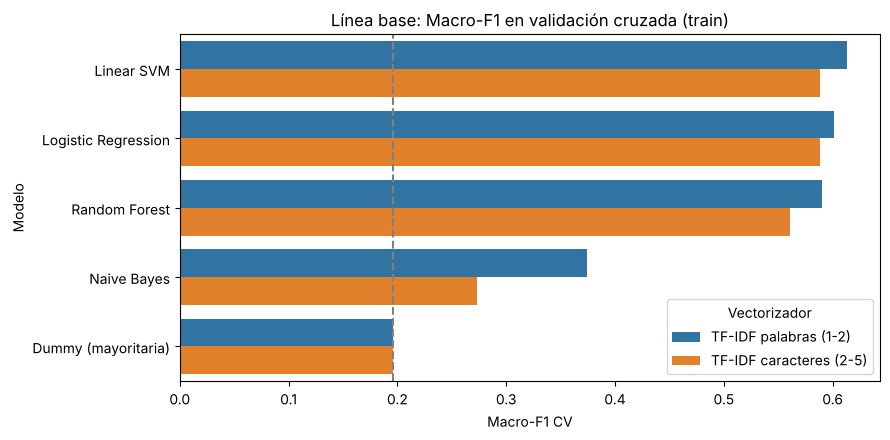

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=resultados_base, y='Modelo', x='Macro-F1 CV', hue='Vectorizador', ax=ax)
ax.set_title('Línea base: Macro-F1 en validación cruzada (train)')
ax.axvline(resultados_base.loc[resultados_base.Modelo.str.startswith('Dummy'), 'Macro-F1 CV'].max(),
           color='gray', ls='--', label='Dummy')
plt.tight_layout(); plt.show()

**Lectura de resultados:** todos los modelos supervisados superan claramente al `DummyClassifier` (macro-F1 ≈ 0.20). Naive Bayes rinde peor porque, con clases desbalanceadas y sin ajuste de priors, tiende a predecir la clase mayoritaria. Los modelos lineales y Random Forest quedan en un rango similar (≈ 0.56–0.61) y la desviación entre folds llega a ±0.06, por lo que el ajuste de hiperparámetros del siguiente paso es el que decide.

# Paso 6 — Ajuste de hiperparámetros

`Pipeline` + `GridSearchCV` con CV estratificada y **macro-F1** como criterio de selección. El vectorizador se incluye como hiperparámetro (palabras vs caracteres) y se ajusta dentro de cada fold, sin ver nunca el test.

> **Uso de LLM (documentar):** prompt sugerido → *"Sugiere rangos razonables de hiperparámetros para TF-IDF + Logistic Regression / Linear SVM / Random Forest con ~500 textos cortos en español, y ayúdame a interpretar la tabla de resultados."*

In [12]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('vec', TfidfVectorizer(sublinear_tf=True)), ('clf', LogisticRegression())])

vec_palabras = {'vec__analyzer': ['word'], 'vec__ngram_range': [(1, 1), (1, 2)], 'vec__min_df': [1, 2]}
vec_chars    = {'vec__analyzer': ['char_wb'], 'vec__ngram_range': [(2, 5), (3, 6)], 'vec__min_df': [2]}

param_grid = []
for vg in (vec_palabras, vec_chars):
    param_grid += [
        {**vg, 'clf': [LogisticRegression(max_iter=3000, class_weight='balanced')], 'clf__C': [0.1, 1, 10, 100]},
        {**vg, 'clf': [LinearSVC(class_weight='balanced')],                         'clf__C': [0.05, 0.1, 0.5, 1, 5]},
        {**vg, 'clf': [RandomForestClassifier(class_weight='balanced', random_state=SEED)],
               'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 30], 'clf__min_samples_leaf': [1, 2]},
    ]

gs = GridSearchCV(pipe, param_grid, scoring='f1_macro', cv=cv, n_jobs=-1, refit=True)
gs.fit(X_train, y_train)

print(f"Mejor macro-F1 CV: {gs.best_score_:.3f}")
print("Mejores parámetros:")
for k, v in gs.best_params_.items(): print(f"  {k}: {v}")

Mejor macro-F1 CV: 0.616
Mejores parámetros:
  clf: LinearSVC(class_weight='balanced')
  clf__C: 0.05
  vec__analyzer: word
  vec__min_df: 2
  vec__ngram_range: (1, 1)


In [13]:
cvr = pd.DataFrame(gs.cv_results_)
cvr['modelo'] = cvr['param_clf'].apply(lambda m: type(m).__name__)
cvr['vectorizador'] = cvr['param_vec__analyzer'].map({'word': 'palabras', 'char_wb': 'caracteres'})
resumen_gs = (cvr.groupby(['modelo', 'vectorizador'])
                 .agg(mejor_macroF1=('mean_test_score', 'max'), n_configs=('mean_test_score', 'size'))
                 .sort_values('mejor_macroF1', ascending=False).round(3))
resumen_gs

,,mejor_macroF1,n_configs
modelo,vectorizador,,
LinearSVC,palabras,0.616,20
LogisticRegression,palabras,0.614,16
RandomForestClassifier,palabras,0.601,32
LinearSVC,caracteres,0.589,10
RandomForestClassifier,caracteres,0.589,16
LogisticRegression,caracteres,0.588,8


**Interpretación:** la diferencia entre las mejores configuraciones de las tres familias (0.60–0.62) es menor que la desviación entre folds (≈ ±0.02–0.06), por lo que no conviene sobreinterpretar diferencias de 1–2 puntos con ~500 ejemplos. Se escoge el pipeline con mayor macro-F1 de validación (`gs.best_estimator_`: TF-IDF de palabras (1,1) + LinearSVC, C = 0.05), y **recién ahora** se toca el conjunto de prueba.

# Paso 7 — Evaluación final en test (20 %) y comparación

Una única evaluación del mejor pipeline sobre el 20 % reservado: accuracy, precisión, recall, macro-F1 y matriz de confusión. Se compara contra el `DummyClassifier`.

> **Uso de LLM (documentar):** prompt sugerido → *"Resume los hallazgos y categoriza los errores de esta lista de comentarios mal clasificados (negación, cláusula contrastante, ironía, etiqueta ruidosa, texto ambiguo)."* **Importante:** anonimiza los comentarios antes de enviarlos a servicios externos.

In [14]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

mejor = gs.best_estimator_
y_pred = mejor.predict(X_test)

dummy = Pipeline([('vec', tfidf_palabras()), ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

def metricas(y_true, y_hat):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_hat, average='macro', zero_division=0)
    return {'Accuracy': accuracy_score(y_true, y_hat), 'Precisión macro': p, 'Recall macro': r, 'Macro-F1': f}

tabla_final = pd.DataFrame({'Dummy': metricas(y_test, y_dummy), 'Mejor modelo': metricas(y_test, y_pred)}).T
print(tabla_final.round(3)); print()
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

              Accuracy  Precisión macro  Recall macro  Macro-F1
Dummy            0.419            0.140         0.333     0.197
Mejor modelo     0.645            0.653         0.634     0.641

              precision    recall  f1-score   support

    negativo      0.641     0.610     0.625        41
     neutral      0.627     0.712     0.667        52
    positivo      0.692     0.581     0.632        31

    accuracy                          0.645       124
   macro avg      0.653     0.634     0.641       124
weighted avg      0.648     0.645     0.644       124



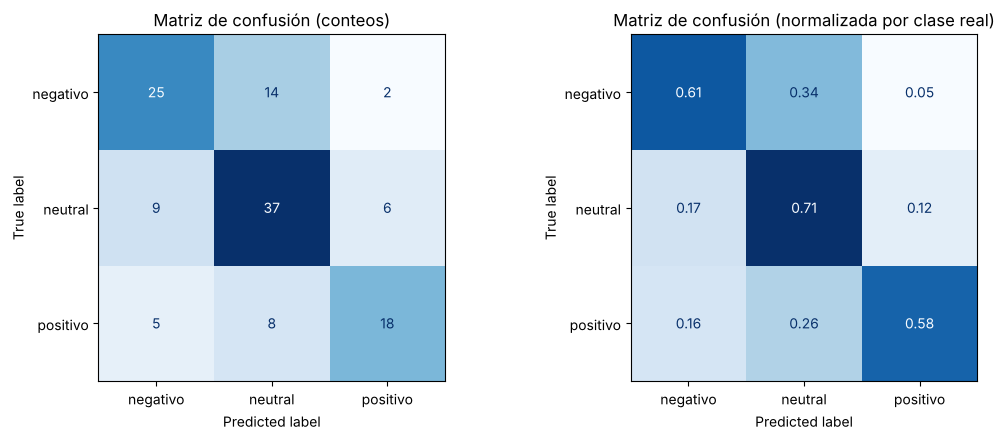

In [15]:
etiquetas = ['negativo', 'neutral', 'positivo']
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=etiquetas, cmap='Blues', ax=axs[0], colorbar=False)
axs[0].set_title('Matriz de confusión (conteos)')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=etiquetas, normalize='true',
                                        values_format='.2f', cmap='Blues', ax=axs[1], colorbar=False)
axs[1].set_title('Matriz de confusión (normalizada por clase real)')
plt.tight_layout(); plt.show()

In [16]:
# Análisis de errores: ¿falla más con comentarios contrastantes (pero/aunque/sin embargo)?
test_df = df.loc[X_test.index, ['feedback_limpio', 'polaridad_final', 'curso', 'es_contrastante']].copy()
test_df['pred'] = y_pred
test_df['correcto'] = test_df.polaridad_final == test_df.pred

print("Accuracy según presencia de cláusula contrastante:")
print(test_df.groupby('es_contrastante')['correcto'].agg(['mean', 'size']).round(3))

errores = test_df[~test_df.correcto]
print(f"\nErrores totales: {len(errores)} de {len(test_df)}")
print(pd.crosstab(errores.polaridad_final, errores.pred, rownames=['real'], colnames=['predicho']))

pd.set_option('display.max_colwidth', 220)
errores[['feedback_limpio', 'polaridad_final', 'pred']].head(8)

Accuracy según presencia de cláusula contrastante:
                  mean  size
es_contrastante             
False            0.815    27
True             0.598    97

Errores totales: 44 de 124
predicho  negativo  neutral  positivo
real                                 
negativo         0       14         2
neutral          9        0         6
positivo         5        8         0


,feedback_limpio,polaridad_final,pred
462,"El diseño de las evaluaciones fue bastante claro y los criterios eran precisos. Sin embargo, hubo veces en las que la retroalimentación sobre los exámenes me resultó confusa y difícil de interpretar, lo cual me dific...",positivo,negativo
342,"El contenido fue interesante pero la retroalimentación no se presentó en forma regular. Además, el material de clase puede mejorar. A pesar de estos puntos, el profesor es amable y explica bien los conceptos.",neutral,negativo
594,"El material de clase fue muy completo y detallado. Me permitió entender los conceptos básicos y avanzados de forma clara. Sin embargo, algunas veces se complicaron los ejemplos y las aplicaciones prácticas podrían ha...",positivo,neutral
149,"El profesor ha organizado bien todo lo relacionado con la materia, pero hubo algunos momentos donde se necesitaron más ejemplos claros para entender algunas conceptos. A pesar de esto, estoy contento con mi rendimien...",neutral,positivo
77,"El curso fue excelente. Los contenidos fueron claros y relevantes, y me permitieron desarrollar habilidades prácticas directamente aplicables en mi carrera. Las actividades y metodología fueron dinámicas y estimulant...",positivo,negativo
459,"El contenido del curso fue muy interesante y útil, pero me ha resultado más difícil entender algunos de los parciales debido a la complejidad de los ejercicios. A pesar de eso, los contenidos del curso estaban bien p...",neutral,negativo
521,"El profesor ha adoptado una metodología muy aburrida y repetitiva, lo cual me ha causado mucha miedo y desinterés por el contenido. A pesar de ello, el material de clase es bastante útil y bien organizado.",negativo,positivo
55,"El contenido fue muy útil y detallado, pero la respuesta a mis correos era inopina.",negativo,positivo


**Hallazgos principales:**
* El mejor pipeline (TF-IDF de palabras + LinearSVC) alcanza **macro-F1 ≈ 0.64 y accuracy ≈ 0.65** en test, frente a ≈ 0.20 / 0.42 del Dummy.
* El macro-F1 en test (0.64) es algo mayor que en validación cruzada (≈ 0.62). Con solo 124 ejemplos de test el intervalo de incertidumbre es amplio (≈ ±0.08), así que ambas cifras son compatibles; se reportan las dos.
* La clase **neutral** es la que más se *sobre-predice* (recall 0.71, precisión 0.63): 14 negativos y 8 positivos terminan clasificados como neutral (22 de 44 errores). La clase **positiva** tiene el menor recall (≈ 0.58).
* La confusión entre polos no es despreciable: 5 positivos se predicen como negativos (16 %) y 2 negativos como positivos (5 %).
* Los comentarios con cláusulas contrastantes (*pero, aunque, sin embargo*) se clasifican bastante peor (accuracy ≈ 0.60, n = 97) que los que no las tienen (≈ 0.82, n = 27); la muestra sin contraste es pequeña, pero la brecha es grande.
* Parte del error proviene del **ruido de etiquetas** del dataset (comentarios con elogios y críticas mezclados o con tono de plantilla etiquetados de forma discutible), no solo del modelo.
* **Corrección respecto a una versión previa:** las correcciones del LLM del Paso 2 se aplicaban por `id`, que se repite entre archivos, y alteraban 14 filas en vez de 4. Ahora se filtra por (archivo, id) con una aserción de unicidad.

# Paso 8 — Guardar el modelo con Joblib y validar la carga (despliegue)

Se serializa el **Pipeline completo** (vectorizador + clasificador) para conservar el preprocesamiento. Si el mejor clasificador no ofrece probabilidades (p. ej. `LinearSVC`), se envuelve con `CalibratedClassifierCV` para poder devolver probabilidades por clase en el MVP. Se registra también la versión de librerías.

In [17]:
import joblib, sys, sklearn, platform, json
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

modelo_final = clone(gs.best_estimator_)
if not hasattr(modelo_final.named_steps['clf'], 'predict_proba'):
    modelo_final.set_params(clf=CalibratedClassifierCV(modelo_final.named_steps['clf'], cv=5))
# Reentrenar con el mismo train (el test sigue sin tocarse para el ajuste)
modelo_final.fit(X_train, y_train)

joblib.dump(modelo_final, 'modelo_polaridad.joblib')
meta = {
    'modelo': type(gs.best_estimator_.named_steps['clf']).__name__,
    'parametros': {k: str(v) for k, v in gs.best_params_.items()},
    'macroF1_cv_train': round(gs.best_score_, 4),
    'macroF1_test': round(f1_score(y_test, y_pred, average='macro'), 4),
    'accuracy_test': round(accuracy_score(y_test, y_pred), 4),
    'clases': list(modelo_final.classes_),
    'n_train': len(X_train), 'n_test': len(X_test),
    'versiones': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                  'joblib': joblib.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
}
json.dump(meta, open('modelo_polaridad_meta.json', 'w'), ensure_ascii=False, indent=2)
print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "modelo": "LinearSVC",
  "parametros": {
    "clf": "LinearSVC(class_weight='balanced')",
    "clf__C": "0.05",
    "vec__analyzer": "word",
    "vec__min_df": "2",
    "vec__ngram_range": "(1, 1)"
  },
  "macroF1_cv_train": 0.6163,
  "macroF1_test": 0.6411,
  "accuracy_test": 0.6452,
  "clases": [
    "negativo",
    "neutral",
    "positivo"
  ],
  "n_train": 494,
  "n_test": 124,
  "versiones": {
    "python": "3.12.3",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "pandas": "3.0.6",
    "numpy": "2.5.4"
  }
}


In [18]:
# Validar carga en "entorno limpio": recargar el archivo y predecir
# (Cargar únicamente archivos joblib de confianza: la deserialización puede ejecutar código arbitrario)
cargado = joblib.load('modelo_polaridad.joblib')

def predecir(comentario: str) -> dict:
    texto = normalizar_texto(comentario)          # mismo preprocesamiento del Paso 2
    if not texto:
        return {'error': 'Texto vacío', 'clase': None, 'probabilidades': {}}
    proba = cargado.predict_proba([texto])[0]
    return {'clase': cargado.classes_[proba.argmax()],
            'probabilidades': {c: round(float(p), 3) for c, p in zip(cargado.classes_, proba)}}

pruebas = [
    "Excelente curso, el profesor explica muy bien y los ejemplos son claros.",
    "Muy mal organizado, las evaluaciones no tienen sentido y nadie responde dudas.",
    "El contenido es interesante, pero el ritmo es demasiado rápido.",
    "El horario es en las mañanas y hay tres parciales.",
    "",            # vacío
    "   ",         # solo espacios
    "😀😀😀",       # solo emojis
]
for t in pruebas: print(repr(t[:60]), '→', predecir(t))

# Coherencia: el modelo recargado debe dar las mismas predicciones que el original en test
assert (cargado.predict(X_test) == modelo_final.predict(X_test)).all()
print("\nOK: predicciones idénticas tras recargar el modelo.")

'Excelente curso, el profesor explica muy bien y los ejemplos' → {'clase': 'positivo', 'probabilidades': {'negativo': 0.107, 'neutral': 0.187, 'positivo': 0.706}}
'Muy mal organizado, las evaluaciones no tienen sentido y nad' → {'clase': 'negativo', 'probabilidades': {'negativo': 0.454, 'neutral': 0.298, 'positivo': 0.247}}
'El contenido es interesante, pero el ritmo es demasiado rápi' → {'clase': 'neutral', 'probabilidades': {'negativo': 0.345, 'neutral': 0.528, 'positivo': 0.127}}
'El horario es en las mañanas y hay tres parciales.' → {'clase': 'negativo', 'probabilidades': {'negativo': 0.622, 'neutral': 0.248, 'positivo': 0.13}}
'' → {'error': 'Texto vacío', 'clase': None, 'probabilidades': {}}
'   ' → {'error': 'Texto vacío', 'clase': None, 'probabilidades': {}}
'😀😀😀' → {'clase': 'negativo', 'probabilidades': {'negativo': 0.428, 'neutral': 0.275, 'positivo': 0.297}}

OK: predicciones idénticas tras recargar el modelo.


## Consideraciones de despliegue (resumen para el informe)

* **Pipeline unificado:** vectorizador + clasificador en un solo objeto; el texto debe pasar antes por `normalizar_texto` (Paso 2).
* **Eficiencia:** el modelo se entrena una vez y se carga desde `modelo_polaridad.joblib`; no se reentrena al iniciar la app.
* **Seguridad:** cargar solo archivos joblib propios/confiables.
* **Compatibilidad:** mismas versiones de scikit-learn entre entrenamiento y producción (ver `modelo_polaridad_meta.json`).
* **Control de versiones:** registrar métricas, parámetros y versión del dataset por cada modelo guardado.
* **Calibración:** como `LinearSVC` no entrega probabilidades, el pipeline se envuelve con `CalibratedClassifierCV` antes de guardarlo.
* **MVP:** ver `app.py` (Streamlit): comentario individual o carga de CSV, con clase y probabilidades.